In [94]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pd.set_option("display.max_colwidth", 90)

# Task 1

In [95]:
CSV_PATH = "spam.csv"
MIRROR_URL = ("https://raw.githubusercontent.com/mohitgupta-omg/"
              "Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv")

if not os.path.exists(CSV_PATH):
    print("spam.csv not found locally -> downloading mirror copy of the Kaggle file...")
    urllib.request.urlretrieve(MIRROR_URL, CSV_PATH)

df_raw = pd.read_csv(CSV_PATH, encoding="latin-1")
print("Raw shape:", df_raw.shape)
df_raw.head()

Raw shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


In [96]:
df_raw.info()
print("\nColumns:", df_raw.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Columns: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


In [97]:
print("Non-null counts in artifact columns:")
print(df_raw[["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]].notna().sum())

Non-null counts in artifact columns:
Unnamed: 2    50
Unnamed: 3    12
Unnamed: 4     6
dtype: int64


In [98]:
# Keep only the primary columns v1 (label) and v2 (text) by dropping the empty remnants
df = df_raw.drop(columns=["Unnamed: 2", "Unnamed: 3", "Unnamed: 4"])

# Rename to meaningful names
df = df.rename(columns={"v1": "label", "v2": "message_text"})

# Encode target: ham -> 0 (legitimate), spam -> 1 (unsolicited)
df["label"] = df["label"].map({"ham": 0, "spam": 1})

print("Clean shape:", df.shape)
print("Columns    :", df.columns.tolist())
print("Label dtype:", df["label"].dtype)
df.head()

Clean shape: (5572, 2)
Columns    : ['label', 'message_text']
Label dtype: int64


,label,message_text
0,0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives around here though"


In [99]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print("\nTotal missing:", int(missing.sum()))
print("Duplicate messages:", int(df.duplicated().sum()), "(kept as-is; the task does not ask for de-duplication)")

Missing values per column:
label           0
message_text    0
dtype: int64

Total missing: 0
Duplicate messages: 403 (kept as-is; the task does not ask for de-duplication)


   class  count  percentage
 ham (0)   4825       86.59
spam (1)    747       13.41


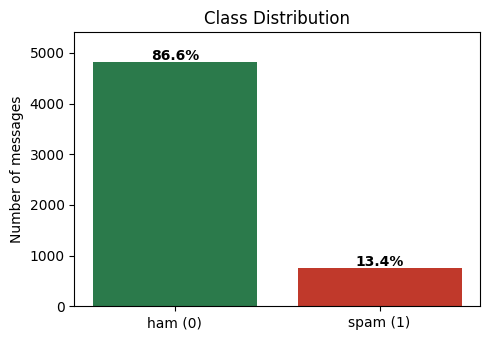

In [100]:
counts = df["label"].value_counts().sort_index()
percent = df["label"].value_counts(normalize=True).sort_index() * 100

dist = pd.DataFrame({
    "class": ["ham (0)", "spam (1)"],
    "count": counts.values,
    "percentage": percent.round(2).values,
})
print(dist.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["ham (0)", "spam (1)"], counts.values, color=["#2b7a4b", "#c0392b"])
for b, p in zip(bars, percent.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 40, f"{p:.1f}%",
            ha="center", fontweight="bold")
ax.set_title("Class Distribution")
ax.set_ylabel("Number of messages")
ax.set_ylim(0, counts.max() * 1.12)
plt.tight_layout()
plt.show()

Average length of HAM  messages : 71.02 characters
Average length of SPAM messages : 138.87 characters
Spam messages are on average 67.8 characters longer (1.96x).


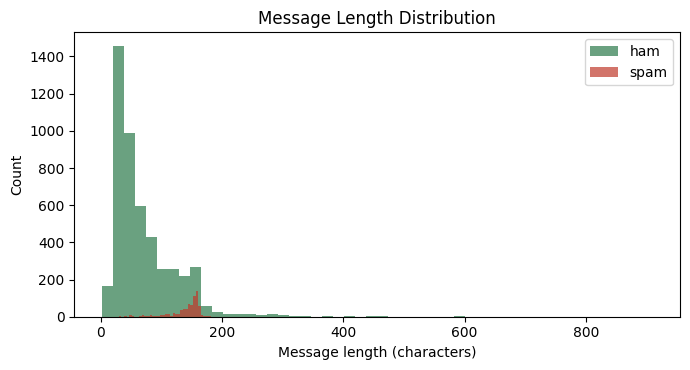

In [85]:
df["char_length"] = df["message_text"].str.len()

avg_len = df.groupby("label")["char_length"].mean()
print(f"Average length of HAM  messages : {avg_len[0]:.2f} characters")
print(f"Average length of SPAM messages : {avg_len[1]:.2f} characters")
print(f"Spam messages are on average {avg_len[1] - avg_len[0]:.1f} characters longer "
      f"({avg_len[1] / avg_len[0]:.2f}x).")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(df.loc[df.label == 0, "char_length"], bins=50, alpha=0.7, label="ham", color="#2b7a4b")
ax.hist(df.loc[df.label == 1, "char_length"], bins=50, alpha=0.7, label="spam", color="#c0392b")
ax.set_xlabel("Message length (characters)")
ax.set_ylabel("Count")
ax.set_title("Message Length Distribution")
ax.legend()
plt.tight_layout()
plt.show()

In [101]:
X = df["message_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=df["label"],
)

print(f"Train size: {len(X_train)}  |  Test size: {len(X_test)}")
split_check = pd.DataFrame({
    "train_spam_%": [y_train.mean() * 100],
    "test_spam_%":  [y_test.mean() * 100],
    "full_spam_%":  [y.mean() * 100],
}).round(2)
print("\nSpam ratio check (should be nearly identical):")
print(split_check.to_string(index=False))

Train size: 4457  |  Test size: 1115

Spam ratio check (should be nearly identical):
 train_spam_%  test_spam_%  full_spam_%
        13.42        13.36        13.41


#Task2

In [102]:
tfidf = TfidfVectorizer(lowercase=True, stop_words="english")

# Fit ONLY on training text, then transform train
X_train_tfidf = tfidf.fit_transform(X_train)

# Test set: transform only (no fitting) -> no leakage
X_test_tfidf = tfidf.transform(X_test)

print("X_train_tfidf shape:", X_train_tfidf.shape)
print("X_test_tfidf  shape:", X_test_tfidf.shape)
print("Vocabulary size    :", len(tfidf.vocabulary_))
sparsity = 1 - X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f"Sparsity (train)   : {sparsity:.4%}")

X_train_tfidf shape: (4457, 7440)
X_test_tfidf  shape: (1115, 7440)
Vocabulary size    : 7440
Sparsity (train)   : 99.8954%


In [88]:
nb_model = MultinomialNB()          # default alpha = 1.0
nb_model.fit(X_train_tfidf, y_train)

print("Model trained.")
print("Laplace smoothing alpha:", nb_model.alpha)
print("Classes:", nb_model.classes_)

Model trained.
Laplace smoothing alpha: 1.0
Classes: [0 1]


In [89]:
y_pred = nb_model.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}  ({acc * 100:.2f}%)")

Test Accuracy: 0.9686  (96.86%)


Confusion Matrix (rows = actual, cols = predicted):
             Pred HAM  Pred SPAM
Actual HAM        966          0
Actual SPAM        35        114

True Negatives  (ham  -> ham ) : 966
False Positives (ham  -> SPAM) : 0   <- legitimate messages wrongly blocked
False Negatives (spam -> ham ) : 35   <- spam that slipped through
True Positives  (spam -> SPAM) : 114


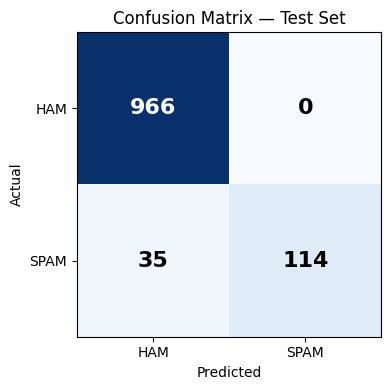

In [90]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix (rows = actual, cols = predicted):")
print(pd.DataFrame(cm, index=["Actual HAM", "Actual SPAM"],
                       columns=["Pred HAM", "Pred SPAM"]))
print(f"\nTrue Negatives  (ham  -> ham ) : {tn}")
print(f"False Positives (ham  -> SPAM) : {fp}   <- legitimate messages wrongly blocked")
print(f"False Negatives (spam -> ham ) : {fn}   <- spam that slipped through")
print(f"True Positives  (spam -> SPAM) : {tp}")

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["HAM", "SPAM"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["HAM", "SPAM"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — Test Set")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

In [91]:
print(classification_report(y_test, y_pred, target_names=["HAM (0)", "SPAM (1)"], digits=4))

              precision    recall  f1-score   support

     HAM (0)     0.9650    1.0000    0.9822       966
    SPAM (1)     1.0000    0.7651    0.8669       149

    accuracy                         0.9686      1115
   macro avg     0.9825    0.8826    0.9246      1115
weighted avg     0.9697    0.9686    0.9668      1115



In [92]:
def predict_message(text: str) -> str:
    """Classify one SMS using the fitted TF-IDF vectorizer + Naive Bayes model."""
    features = tfidf.transform([text])
    pred = nb_model.predict(features)[0]
    return "SPAM" if pred == 1 else "HAM"

def spam_probability(text: str) -> float:
    return float(nb_model.predict_proba(tfidf.transform([text]))[0, 1])

samples = [
    "Hey, are we still meeting for lunch today?",
    "Congratulations! You have won a $1,000 gift card. Call now to claim.",
]

print(f"{'Predicted':<10} | {'P(spam)':<8} | Message")
print("-" * 90)
for msg in samples:
    print(f"{predict_message(msg):<10} | {spam_probability(msg):<8.3f} | {msg}")

Predicted  | P(spam)  | Message
------------------------------------------------------------------------------------------
HAM        | 0.002    | Hey, are we still meeting for lunch today?
SPAM       | 0.853    | Congratulations! You have won a $1,000 gift card. Call now to claim.


In [93]:
feature_names = np.array(tfidf.get_feature_names_out())
log_ratio = nb_model.feature_log_prob_[1] - nb_model.feature_log_prob_[0]

top_spam = feature_names[np.argsort(log_ratio)[::-1][:15]]
top_ham = feature_names[np.argsort(log_ratio)[:15]]

print("Top 15 SPAM-indicative words:", ", ".join(top_spam))
print("Top 15 HAM-indicative words :", ", ".join(top_ham))

Top 15 SPAM-indicative words: claim, prize, 150p, www, uk, tone, 18, guaranteed, 1000, cs, 500, nokia, service, 16, ringtone
Top 15 HAM-indicative words : gt, lt, ll, ok, later, lor, da, home, come, sorry, ì_, going, got, doing, wat
